![](https://imgs.xkcd.com/comics/travelling_salesman_problem.png)

In [13]:
import random
import math
import matplotlib.pyplot as plt
from tsp_generator import generate_instance, generate_circular_instance

## Evolution of a Salesperson

In the Traveling Salesperson Problem (TSP), one is given a set of cities and the distances between them. The aim is to construct a tour that visits every city exactly once, while minimizing the total length of the tour. This is an NP-hard problem (read: we don't have good ways to solve this problem efficiently for all possible input cases), so genetic algorithms offer one way to find approximate solutions.

### The `Tour` class

Each individual in our population will be a candidate tour, which we will represent using a tuple. So for example, if we have a TSP instance with 5 cities, then one possible tour could be `(1, 4, 2, 0, 3)`, i.e., we follow the route City 1 --> City 4 --> ... --> City 3. Given a tour, it would also be handy to have some utility functions to do some useful calculations for us, like computing its length, or mutating it. While we could write individual functions for each of these operations, it's much cleaner from a design standpoint to encapsulate it all in a single, custom class. This is the purpose of the `Tour` class below: it forms a wrapper around a tuple representing a tour and provides some useful methods to manipulate and modify tours. **Your main task on this activity is to provide implementations for the methods `mutate` and `crossover` below.**

#### Aside: What's with this tuple stuff?

Why not just use a list? What's the difference between a tuple and a list anyway? The first difference is cosmetic: lists use square brackets (for example, `[1, 4, 2, 0, 3]`) whereas tuples uses parentheses (`(1, 4, 2, 0, 3)`). The more consequential difference, however, is the following fact: **tuples are immutable**. In other words, the contents of a tuple, once created, cannot be modified. Even more concretely, here's the difference:

```
>>> foo = [1, 4, 2, 0, 3]
>>> foo[3] = 1 # this is ok! foo is now [1, 4, 2, 1, 3]

>>> bar = (1, 4, 2, 0, 3)
>>> bar[3] = 1 # will throw an exception! you cannot modify bar once it's been created
```

This may seem needlessly limiting, but when designing classes, immutability is actually a desirable property! It makes the behavior of the objects you create much easier to reason about and avoids nasty memory bugs that can arise from reference aliasing. Indeed, when you implement the `mutate` and `crossover` methods below, you should take care to ensure that `Tour` objects remain immutable, i.e., don't ever modify the `self` object itself but instead create and return new `Tour` objects.

In [128]:
class Tour:
    def __init__(self, distances, order=None):
        self.num_cities = len(distances)
        self.distances = distances        
        if order:  # if a visit order is provided, use it
            if type(order) != type(()):
                raise ValueError('order must be specified using a tuple')
            self.tour = order
        else:
            # otherwise, generate a new visit order as a random permutation
            # of the cities and store it as an immutable tuple
            self.tour = list(range(self.num_cities))
            random.shuffle(self.tour)
            self.tour = tuple(self.tour)
        self.fitness = self.get_fitness()

    def __repr__(self):
        """ A printable representation of this tour. """
        return self.tour.__repr__()
    
    def __hash__(self):
        """ 
        A hash code for this tour (necessary if you want to place Tours in
        a set or a dict).
        """
        return self.tour.__hash__()
    
    def get_fitness(self):
        """ Returns the total length of this tour. """
        if not self.is_legal_tour():
            print(self.tour)
            raise ValueError("Attempt to get the fitness of an illegal tour.")

        total = 0
        for i in range(1, len(self.distances)):
            current = self.tour[i]
            previous = self.tour[i-1]
            total += self.distances[current][previous]
        return total
    
    def is_legal_tour(self):
        """ 
        Determines if the current tour is legal (i.e., visits every city
        exactly once) or not. 
        """
        cities = set(self.tour)
        largest = max(self.tour)
        smallest = min(self.tour)
        # tour is legal if every city between 0 and N-1 appears exactly once
        return (len(cities) == self.num_cities and
                smallest == 0 and
                largest == self.num_cities - 1)
    
    def mutate(self):
        """ 
        Return a *new* Tour object that is a mutated version of this tour.

        DO NOT MODIFY self!
        """
        random1 = random.randint(0, self.num_cities-1)
        temp = random.randint(0, self.num_cities-1)

        num1 = self.tour[random1]
        num2 = self.tour[temp]
        myList = []
        
        for i in range(len(self.tour)):
            if i == random1:
                myList.append(num2)
            elif i == temp:
                myList.append(num1)
            else:
                myList.append(self.tour[i])
        
        return Tour(distances, tuple(myList))
        
    def crossover(self, other):
        """
        Return a *new* Tour object that is an offspring produced by
        crossing over this Tour with the other Tour.
        
        DO NOT MODIFY self or other!
        """

        partition = random.randint(1,self.num_cities-1)

        coin = random.randint(0,1)

        if coin:
            half1 = self.tour[0:partition+1]
            half2 = other.tour[partition:self.num_cities-1]
        else:
            half1 = other.tour[0:partition+1]
            half2 = self.tour[partition:self.num_cities-1]

        # print(half1)
        # print(half2)
        newList = list(half1)
        newList.extend(list(half2))
        dupIndexes = []
        notInList = []
        # print(newList)
        
        for i in range(len(newList)):
            if i not in newList:
                notInList.append(i)
            if newList[i] in newList[0:i]:
                dupIndexes.append(i)

        # print(notInList)
        # print(dupIndexes)
        for i in range(len(dupIndexes)):
            tempRand = random.randint(0, len(notInList)-1)
            newList[dupIndexes[i]] = notInList[tempRand]
            notInList.remove(notInList[tempRand])
        # print(newList)
        #return Tour(distances, tuple (newList))
        return Tour(distances, tuple(newList))   
        
        
        # COMPLETE ME!

### Some utility functions

Here are some helper functions that will help us write the main evolutionary loop. You don't have to modify these, but here's a brief blurb about each.
* `initialize_population`: creates a seed population of randomly generated tours
* `fitness_to_weights`: converts the fitnesses of the individuals in the population into weights that can be used to select individuals for crossover/mutation. This conversion is necessary because in this domain, smaller fitness (i.e., tour length) is better. But when we select individuals from the population, it's easier (i.e., we can reuse library functions) if larger numbers correspond to fitter individuals. To avoid confusion, we will refer to these transformed values as "weights".

In [129]:
def initialize_population(distances, size):
    population = []
    for i in range(size):
        population.append(Tour(distances))
    return population


def fitness_to_weights(population):
    fitnesses = [t.fitness for t in population]
    largest = max(fitnesses)
    weights = [largest - f for f in fitnesses]
    return weights

### The Genetic Algorithm loop

Time to let evolution do its thing. First, some constants. You may find it helpful to set some of these to smaller values when debugging.

In [172]:
NUM_CITIES = 20
NUM_GENS = 1000
MUTATION_PROB = 0.02
CROSSOVER_PROB = 0.1
POPULATION_SIZE = 500

Each new generation comprises:
* 10% of individuals generated by mutation,
* 60% of individuals generated by crossover, and
* 30% of individuals generated by cloning.

Selection for each of the above operations is performed using fitness proportionate selection (aka Roulette wheel selection). Also, for each generation, we keep track of the fittest individual in that generation so that we can plot the progress of our optimization at the end. You do not need to modify the code in this cell, but you may want to understand its structure at a high level.

In [175]:



distances, opt = generate_circular_instance(NUM_CITIES)  # creates a random TSP problem instance
current_gen = initialize_population(distances, POPULATION_SIZE)
best = []

i = 0
for i in range(NUM_GENS):
    next_gen = []
    weights = fitness_to_weights(current_gen)
    
    # populate next generation
    for j in range(POPULATION_SIZE):
        parent1 = random.choices(current_gen, weights)[0]
        flip = random.random()
        if flip <= MUTATION_PROB:  # mutation
            next_gen.append(parent1.mutate())
        elif flip <= CROSSOVER_PROB + MUTATION_PROB:  # crossover
            parent2 = random.choices(current_gen, weights)[0]
            next_gen.append(parent1.crossover(parent2))
        else:  # clone
            next_gen.append(parent1)
            
    # remember the best individual in this generation
    best_tour = min(current_gen, key=lambda t: t.fitness)
    best.append(best_tour)
    
    # reset the current gen
    current_gen = next_gen
print(opt)

297.22548357643853


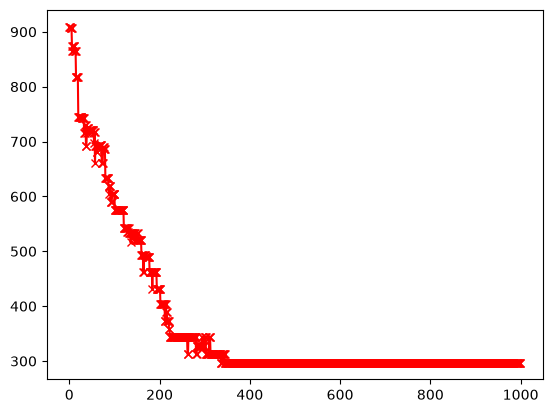

In [176]:
plt.plot(range(NUM_GENS), [t.fitness for t in best], 'rx-')

### Extension 1: Benchmarking the Solution Quality

Let's systematically probe the quality of the solutions found by your genetic algorithm. In the previous cell, the GA loop invoked the `generate_instance` function from `tsp_generator.py` to generate random instances to solve. Modify the code instead to use `generate_circular_instance`. This latter function generates TSP instances where the length of the optimal path is known ahead of time (see documentation in `tsp_generator.py`). How close does your GA get to this known optimum on average? In the field of approximation algorithms, this is typically quantified by measuring the fraction of optimal, i.e., by computing $k/OPT$ where $k$ is the length of the path found by your GA and $OPT$ denotes the optimal tour length. How does your implementation's fraction of OPT change as you vary the number of generations of evolution and `NUM_CITIES`?

### Extension 2: Alternative Selection Methods

The current approach uses fitness proportionate selection to pick parents for crossover and mutation. Implement a different selection algorithm to study its impact on your GA's performance. For example, see this paper: [A Comparison of Selection Schemes Used in Evolutionary Algorithms](https://ieeexplore.ieee.org/document/6791924)